# NASA B0005 Battery Capacity Degradation and Machine Learning

This notebook analyzes the **NASA B0005 lithium-ion battery dataset** to study discharge-capacity degradation and evaluate several capacity-estimation approaches.

## Project workflow
1. Extract discharge records and calculate capacity-based state of health (SOH).
2. Visualize capacity degradation and explore correlations between discharge features and measured capacity.
3. Compare trend-based models using discharge number alone.
4. Evaluate retrospective capacity estimation using measurements from a completed discharge.
5. Compare rolling one-step-ahead estimates from lagged linear regression with a persistence baseline.
6. Export the processed tables and model metrics.

## Important interpretation notes
- Capacity-based SOH is calculated relative to the first recorded discharge in this dataset.
- Features measured during a completed discharge are not available before that discharge begins. The full-feature experiment is therefore a **retrospective estimate**, not a pre-discharge forecast.
- The lagged experiment is a **rolling one-step-ahead evaluation**: previous measured capacities are available for each successive test prediction.
- This notebook evaluates **one battery (B0005) only**. Performance on other batteries has not been tested.


## 1. Imports and dataset path




In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MAT_FILE = Path("B0005.mat")
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MAT_FILE.exists():
    raise FileNotFoundError(
        "B0005.mat was not found. Place the dataset in the same folder as this notebook, or update MAT_FILE to a local path."
    )

print("Dataset found.")
print("Results will be saved to:", OUTPUT_DIR)


Dataset found.
Results will be saved to: results


## 2. Load the MATLAB structure

The NASA file is expected to contain a top-level `B0005` variable with a `cycle` field. In the common MATLAB structure, the cycle array has shape `(1, 616)`. Access each raw record as `cycles[0, i]`, not `cycles[i]`.


In [3]:
mat = loadmat(MAT_FILE)
if "B0005" not in mat:
    raise KeyError("The MATLAB file does not contain a top-level 'B0005' variable.")

battery = mat["B0005"]
cycles = battery["cycle"][0, 0]

print("Cycle array shape:", cycles.shape)
print("Cycle fields:", cycles.dtype.names)

Cycle array shape: (1, 616)
Cycle fields: ('type', 'ambient_temperature', 'time', 'data')


## 3. Extract discharge capacity and curve features

`record_index` is the zero-based index of the record in the raw MATLAB array. `discharge_number` counts only discharge records, starting at 1.

In [4]:
def matlab_text(value):
    # Unwrap nested single-element MATLAB arrays.
    while isinstance(value, np.ndarray) and value.size == 1:
        value = value.item()
    if isinstance(value, bytes):
        return value.decode("utf-8", errors="replace").strip()
    if isinstance(value, str):
        return value.strip()
    arr = np.asarray(value)
    if arr.dtype.kind in {"U", "S"}:
        return "".join(arr.astype(str).ravel()).strip()
    if arr.dtype == object and arr.size:
        return matlab_text(arr.ravel()[0])
    return str(value).strip()


def numeric_array(value):
    while isinstance(value, np.ndarray) and value.size == 1 and value.dtype == object:
        value = value.item()
    return np.asarray(value, dtype=float).ravel()


def scalar_float(value):
    arr = numeric_array(value)
    if arr.size == 0:
        raise ValueError("Expected a numeric value but found an empty field.")
    return float(arr[0] if arr.size == 1 else arr[-1])


capacity_records = []
feature_records = []
discharge_number = 0

for record_index in range(cycles.shape[1]):
    cycle = cycles[0, record_index]
    cycle_type = matlab_text(cycle["type"]).lower()

    if "discharge" not in cycle_type:
        continue

    discharge_number += 1
    payload = cycle["data"][0, 0]

    voltage = numeric_array(payload["Voltage_measured"])
    current = numeric_array(payload["Current_measured"])
    temperature = numeric_array(payload["Temperature_measured"])
    time_s = numeric_array(payload["Time"])
    capacity_ah = scalar_float(payload["Capacity"])

    if min(len(voltage), len(current), len(temperature), len(time_s)) == 0:
        raise ValueError(f"Empty measurement array in raw record {record_index}.")

    # Keep the measurements aligned if array lengths differ.
    n = min(len(voltage), len(current), len(temperature), len(time_s))
    voltage, current = voltage[:n], current[:n]
    temperature, time_s = temperature[:n], time_s[:n]

    duration_s = float(time_s[-1] - time_s[0])

    capacity_records.append({
        "discharge_number": discharge_number,
        "record_index": record_index,
        "time_points": int(n),
        "capacity_Ah": capacity_ah,
        "initial_voltage_V": float(voltage[0]),
        "final_voltage_V": float(voltage[-1]),
    })

    feature_records.append({
        "record_index": record_index,
        "duration_seconds": duration_s,
        "duration_minutes": duration_s / 60,
        "mean_voltage_V": float(np.mean(voltage)),
        "min_voltage_V": float(np.min(voltage)),
        "max_voltage_V": float(np.max(voltage)),
        "mean_current_A": float(np.mean(current)),
        "mean_temperature_C": float(np.mean(temperature)),
        "max_temperature_C": float(np.max(temperature)),
        "temperature_rise_C": float(np.max(temperature) - temperature[0]),
        "voltage_drop_V": float(voltage[0] - voltage[-1]),
        "time_points": int(n),
    })

df_capacity = pd.DataFrame(capacity_records)
df_features = pd.DataFrame(feature_records)

if df_capacity.empty:
    raise ValueError("No discharge records were extracted; check the MATLAB structure.")

first_capacity = float(df_capacity.loc[0, "capacity_Ah"])
df_capacity["SOH_percent"] = df_capacity["capacity_Ah"] / first_capacity * 100
df_capacity["capacity_change_Ah"] = first_capacity - df_capacity["capacity_Ah"]
df_capacity["capacity_loss_percent"] = df_capacity["capacity_change_Ah"] / first_capacity * 100

print("Discharge records extracted:", len(df_capacity))
print("Capacity table shape:", df_capacity.shape)
print("Feature table shape:", df_features.shape)
display(df_capacity.head())
display(df_features.head())

Discharge records extracted: 168
Capacity table shape: (168, 9)
Feature table shape: (168, 12)


,discharge_number,record_index,time_points,capacity_Ah,initial_voltage_V,final_voltage_V,SOH_percent,capacity_change_Ah,capacity_loss_percent
0,1,1,197,1.856487,4.191492,3.277170,100.000000,0.000000,0.000000
1,2,3,196,1.846327,4.189773,3.300245,99.452721,0.010160,0.547279
2,3,5,195,1.835349,4.188187,3.327451,98.861386,0.021138,1.138614
3,4,7,194,1.835263,4.188461,3.314182,98.856718,0.021225,1.143282
4,5,9,194,1.834646,4.188299,3.305497,98.823482,0.021842,1.176518


,record_index,duration_seconds,duration_minutes,mean_voltage_V,min_voltage_V,max_voltage_V,mean_current_A,mean_temperature_C,max_temperature_C,temperature_rise_C,voltage_drop_V,time_points
0,1,3690.234,61.503900,3.529829,2.612467,4.191492,-1.818702,32.572328,38.982181,14.652147,0.914322,197
1,3,3672.344,61.205733,3.537320,2.587209,4.189773,-1.817560,32.725235,39.033398,14.335646,0.889528,196
2,5,3651.641,60.860683,3.543737,2.651917,4.188187,-1.816487,32.642862,38.818797,14.084531,0.860736,195
3,7,3631.563,60.526050,3.543666,2.592948,4.188461,-1.825589,32.514876,38.762305,14.108068,0.874279,194
4,9,3629.172,60.486200,3.542343,2.547420,4.188299,-1.826114,32.382349,38.665393,14.140596,0.882802,194


## 4. Check the extracted data

Capacity-based SOH is defined relative to the first recorded discharge:

SOH(%) = [{Qm}/{Qr}] x 100 ,
Qm - measured discharge capacity at the current cycle (Ah).
Qr - reference capacity, often the initial measured capacity or rated capacity (Ah).

This is a dataset-relative capacity indicator, not an independent laboratory measurement of battery health.

In [17]:
print("Missing values in capacity table:", int(df_capacity.isna().sum().sum()))
print("Missing values in feature table:", int(df_features.isna().sum().sum()))
display(df_capacity["capacity_Ah"].describe().to_frame())

print(f"First capacity: {first_capacity:.6f} Ah")
print(f"Final capacity: {df_capacity['capacity_Ah'].iloc[-1]:.6f} Ah")
print(f"Final SOH: {df_capacity['SOH_percent'].iloc[-1]:.2f}%")
print(f"Minimum capacity: {df_capacity['capacity_Ah'].min():.6f} Ah")
print(f"Minimum SOH: {df_capacity['SOH_percent'].min():.2f}%")

Missing values in capacity table: 0
Missing values in feature table: 0


,capacity_Ah
count,168.000000
mean,1.572502
std,0.190413
min,1.287453
25%,1.390021
50%,1.557085
75%,1.769163
max,1.856487


First capacity: 1.856487 Ah
Final capacity: 1.325079 Ah
Final SOH: 71.38%
Minimum capacity: 1.287453 Ah
Minimum SOH: 69.35%


## 5. Visualize capacity degradation

The overall pattern should decline, though individual records may show small upward movements. Do not automatically interpret every rebound as physical battery recovery.

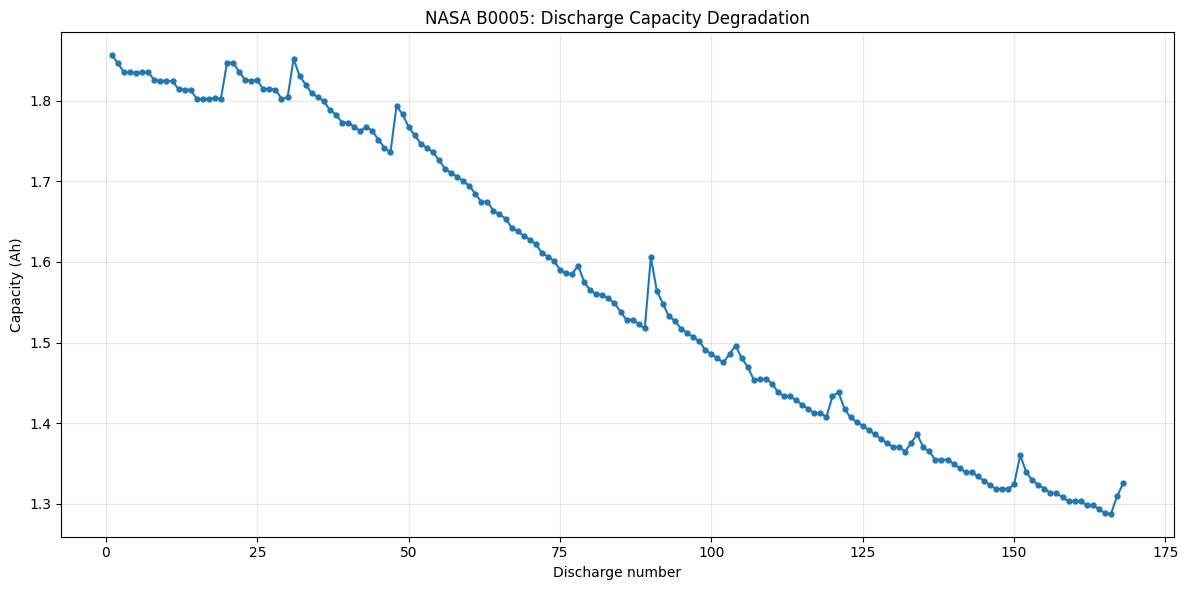

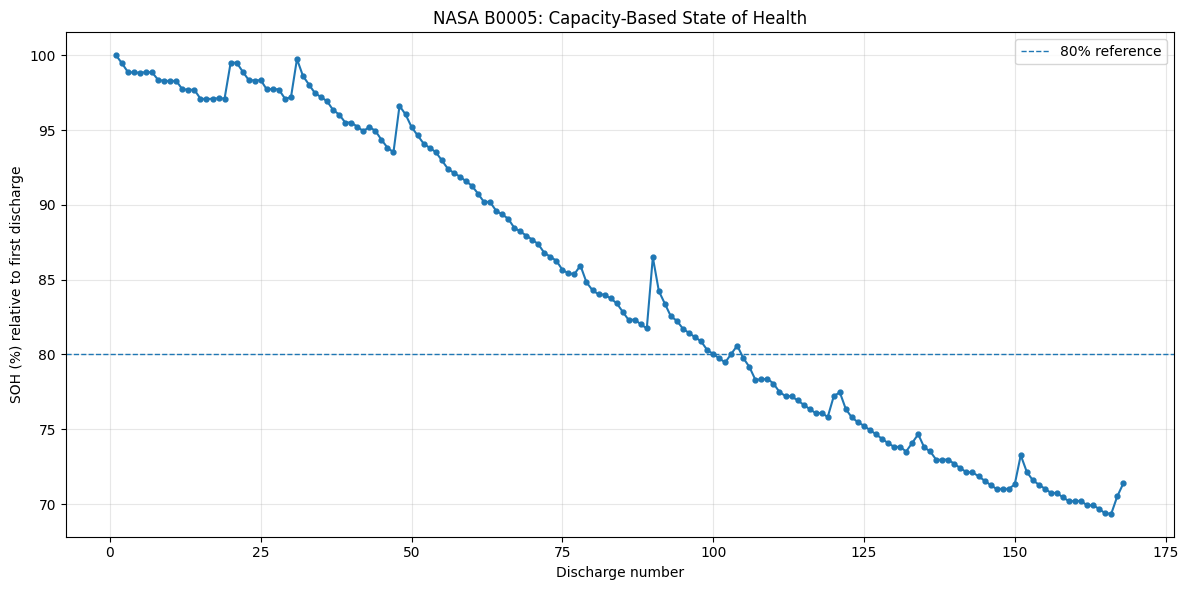

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_capacity["discharge_number"], df_capacity["capacity_Ah"],
        marker="o", markersize=3.5, linewidth=1.5)
ax.set(title="NASA B0005: Discharge Capacity Degradation",
       xlabel="Discharge number", ylabel="Capacity (Ah)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_capacity["discharge_number"], df_capacity["SOH_percent"],
        marker="o", markersize=3.5, linewidth=1.5)
ax.axhline(80, linestyle="--", linewidth=1, label="80% reference")
ax.set(title="NASA B0005: Capacity-Based State of Health",
       xlabel="Discharge number", ylabel="SOH (%) relative to first discharge")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

#Saving plots in png format
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

plt.savefig(
    FIGURES_DIR / "capacity_degradation.png",
    dpi=300,
    bbox_inches="tight"
)


## 6. Merge features with capacity labels

The merge uses `record_index` to preserve the alignment between each discharge's features and its measured capacity.

In [7]:
df_ml = (
    df_features
    .merge(
        df_capacity[["record_index", "discharge_number", "capacity_Ah", "SOH_percent"]],
        on="record_index",
        how="inner",
        validate="one_to_one",
    )
    .sort_values("discharge_number")
    .reset_index(drop=True)
)

print("Merged table shape:", df_ml.shape)
print("Missing values:", int(df_ml.isna().sum().sum()))
display(df_ml.head())

Merged table shape: (168, 15)
Missing values: 0


,record_index,duration_seconds,duration_minutes,mean_voltage_V,min_voltage_V,max_voltage_V,mean_current_A,mean_temperature_C,max_temperature_C,temperature_rise_C,voltage_drop_V,time_points,discharge_number,capacity_Ah,SOH_percent
0,1,3690.234,61.503900,3.529829,2.612467,4.191492,-1.818702,32.572328,38.982181,14.652147,0.914322,197,1,1.856487,100.000000
1,3,3672.344,61.205733,3.537320,2.587209,4.189773,-1.817560,32.725235,39.033398,14.335646,0.889528,196,2,1.846327,99.452721
2,5,3651.641,60.860683,3.543737,2.651917,4.188187,-1.816487,32.642862,38.818797,14.084531,0.860736,195,3,1.835349,98.861386
3,7,3631.563,60.526050,3.543666,2.592948,4.188461,-1.825589,32.514876,38.762305,14.108068,0.874279,194,4,1.835263,98.856718
4,9,3629.172,60.486200,3.542343,2.547420,4.188299,-1.826114,32.382349,38.665393,14.140596,0.882802,194,5,1.834646,98.823482


## 7. Feature correlations

Correlations show which variables move together in this dataset; they do not prove causation. Correlated predictors can also make individual regression coefficients difficult to interpret.

,capacity_Ah
capacity_Ah,1.000000
mean_voltage_V,0.982357
duration_seconds,0.975523
voltage_drop_V,0.965193
max_voltage_V,-0.222038
time_points,-0.342844
min_voltage_V,-0.487071
mean_temperature_C,-0.809744
mean_current_A,-0.933321
max_temperature_C,-0.935272


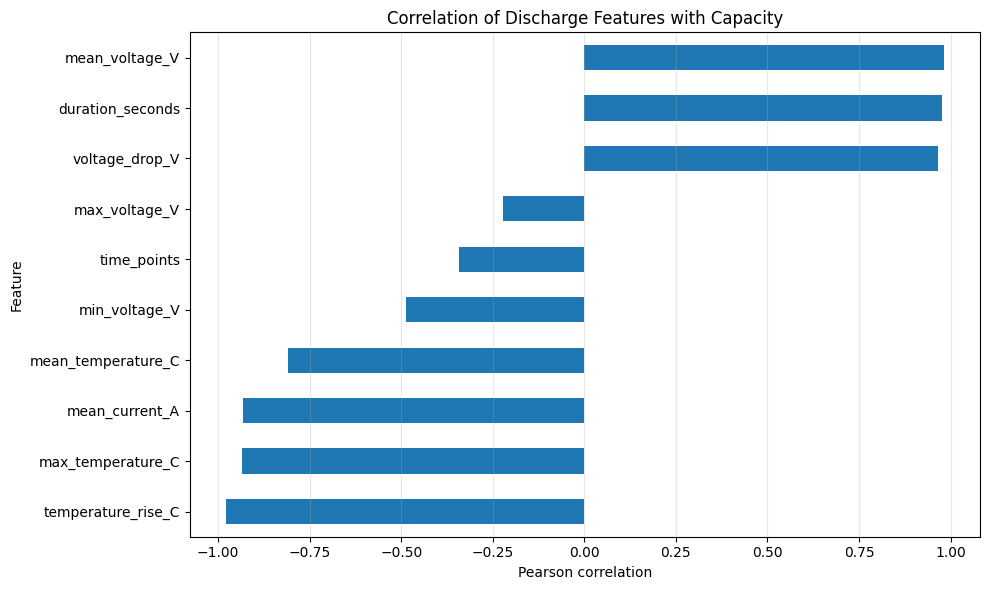

In [8]:
correlation_columns = [
    "capacity_Ah", "duration_seconds", "mean_voltage_V", "min_voltage_V",
    "max_voltage_V", "mean_current_A", "mean_temperature_C",
    "max_temperature_C", "temperature_rise_C", "voltage_drop_V", "time_points"
]
corr = df_ml[correlation_columns].corr(numeric_only=True)
display(corr[["capacity_Ah"]].sort_values("capacity_Ah", ascending=False))

feature_corr = corr["capacity_Ah"].drop("capacity_Ah").sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
feature_corr.plot(kind="barh", ax=ax)
ax.set(title="Correlation of Discharge Features with Capacity",
       xlabel="Pearson correlation", ylabel="Feature")
ax.grid(True, axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

## 8. Chronological train/test split

Use the first 80% of discharges for training and the last 20% for testing, without random shuffling. For 168 discharges, this gives 134 training records and 34 test records.

In [9]:
split_idx = int(len(df_ml) * 0.80)
train_ml = df_ml.iloc[:split_idx].copy()
test_ml = df_ml.iloc[split_idx:].copy()

print(f"Training discharges: {len(train_ml)} "
      f"({train_ml['discharge_number'].min()}–{train_ml['discharge_number'].max()})")
print(f"Test discharges: {len(test_ml)} "
      f"({test_ml['discharge_number'].min()}–{test_ml['discharge_number'].max()})")

def regression_metrics(actual, predicted):
    return {
        "MAE (Ah)": mean_absolute_error(actual, predicted),
        "RMSE (Ah)": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted),
    }

y_train = train_ml["capacity_Ah"]
y_test_ml = test_ml["capacity_Ah"]

Training discharges: 134 (1–134)
Test discharges: 34 (135–168)


## 9. Experiment 1 — Use discharge number alone

This is a simple trend-based model. Random forests are included for comparison, but tree-based models can struggle to extrapolate beyond training values.

,Model,MAE (Ah),RMSE (Ah),R2 Score
0,Linear regression: discharge number,0.0309,0.0388,-2.0554
1,Random forest: discharge number,0.0506,0.0553,-5.1923
2,Last observed capacity baseline,0.0612,0.0651,-7.5803
3,Training mean baseline,0.3104,0.3111,-195.2336


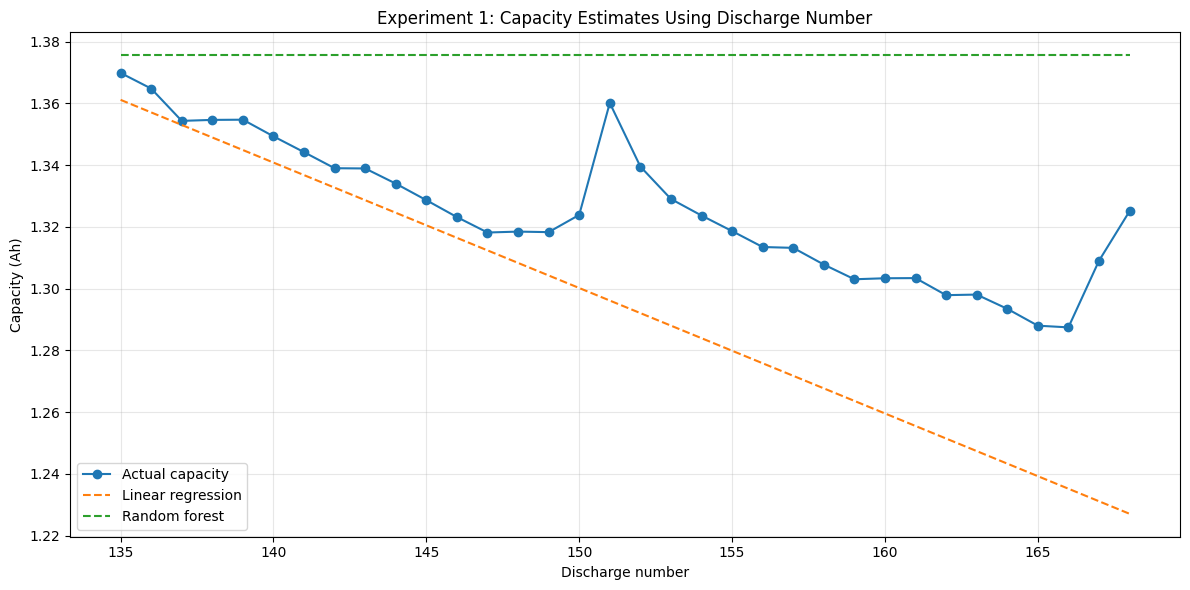

In [10]:
X_train_cycle = train_ml[["discharge_number"]]
X_test_cycle = test_ml[["discharge_number"]]

trend_lr = LinearRegression().fit(X_train_cycle, y_train)
trend_lr_pred = trend_lr.predict(X_test_cycle)

trend_rf = RandomForestRegressor(
    n_estimators=300, max_depth=5, min_samples_leaf=3, random_state=42
).fit(X_train_cycle, y_train)
trend_rf_pred = trend_rf.predict(X_test_cycle)

last_observed_pred = np.repeat(float(y_train.iloc[-1]), len(y_test_ml))
training_mean_pred = np.repeat(float(y_train.mean()), len(y_test_ml))

trend_results_df = pd.DataFrame([
    {"Model": "Linear regression: discharge number", **regression_metrics(y_test_ml, trend_lr_pred)},
    {"Model": "Random forest: discharge number", **regression_metrics(y_test_ml, trend_rf_pred)},
    {"Model": "Last observed capacity baseline", **regression_metrics(y_test_ml, last_observed_pred)},
    {"Model": "Training mean baseline", **regression_metrics(y_test_ml, training_mean_pred)},
]).sort_values("MAE (Ah)")
display(trend_results_df.round(4))

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(test_ml["discharge_number"], y_test_ml, marker="o", label="Actual capacity")
ax.plot(test_ml["discharge_number"], trend_lr_pred, linestyle="--", label="Linear regression")
ax.plot(test_ml["discharge_number"], trend_rf_pred, linestyle="--", label="Random forest")
ax.set(title="Experiment 1: Capacity Estimates Using Discharge Number",
       xlabel="Discharge number", ylabel="Capacity (Ah)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 10. Experiment 2 — Retrospective estimate using completed-discharge features

The predictors include duration, voltage, current, and temperature summaries from the same completed discharge whose capacity is being estimated. These measurements are not available before that discharge begins, so this is **retrospective estimation**, not prospective forecasting.

,Model,MAE (Ah),RMSE (Ah),R2 Score
0,Linear regression: completed-discharge features,0.0027,0.0029,0.9831
1,Random forest: completed-discharge features,0.0500,0.0545,-5.0229


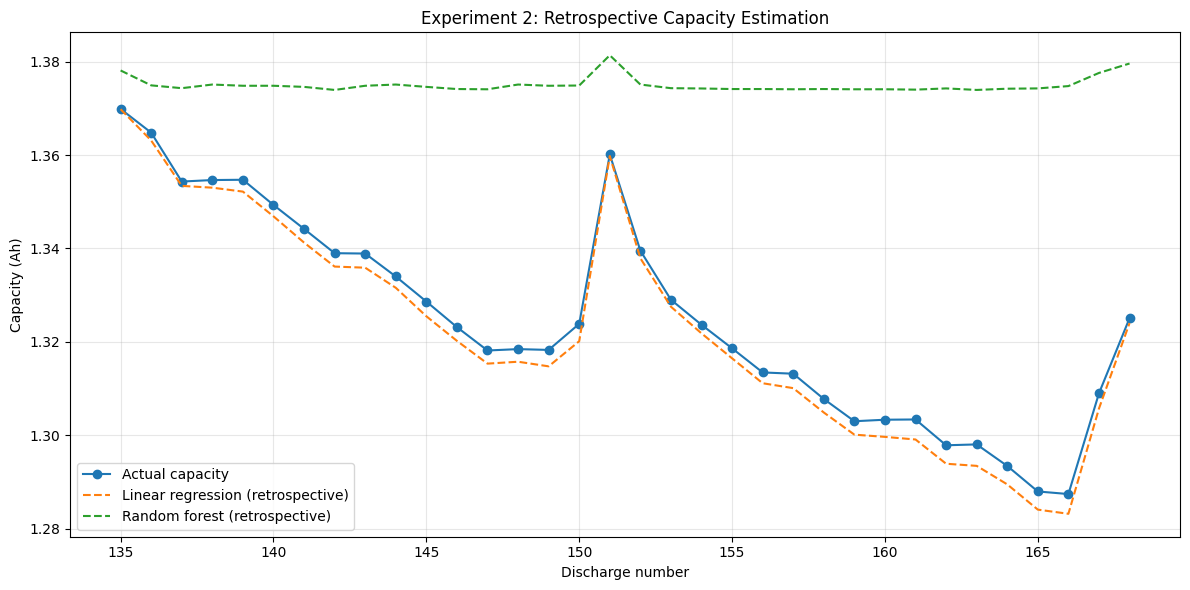

In [11]:
feature_columns = [
    "duration_seconds", "mean_voltage_V", "min_voltage_V", "mean_current_A",
    "mean_temperature_C", "max_temperature_C", "temperature_rise_C",
    "voltage_drop_V", "time_points"
]

X_train_features = train_ml[feature_columns]
X_test_features = test_ml[feature_columns]

feature_lr = LinearRegression().fit(X_train_features, y_train)
feature_lr_pred = feature_lr.predict(X_test_features)

feature_rf = RandomForestRegressor(
    n_estimators=300, max_depth=5, min_samples_leaf=3, random_state=42
).fit(X_train_features, y_train)
feature_rf_pred = feature_rf.predict(X_test_features)

feature_results_df = pd.DataFrame([
    {"Model": "Linear regression: completed-discharge features",
     **regression_metrics(y_test_ml, feature_lr_pred)},
    {"Model": "Random forest: completed-discharge features",
     **regression_metrics(y_test_ml, feature_rf_pred)},
])
display(feature_results_df.round(4))

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(test_ml["discharge_number"], y_test_ml, marker="o", label="Actual capacity")
ax.plot(test_ml["discharge_number"], feature_lr_pred, linestyle="--",
        label="Linear regression (retrospective)")
ax.plot(test_ml["discharge_number"], feature_rf_pred, linestyle="--",
        label="Random forest (retrospective)")
ax.set(title="Experiment 2: Retrospective Capacity Estimation",
       xlabel="Discharge number", ylabel="Capacity (Ah)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretation:** compare the metrics calculated above rather than relying on a fixed score. A strong retrospective score should not be described as pre-discharge forecasting because the predictors come from the completed discharge. The features are also correlated with one another, so this experiment is best treated as an exploratory estimate rather than evidence of a deployable prediction system.


## 11. Experiment 3 — One-step-ahead estimate from the two previous capacities

This uses the previous two measured capacities as inputs. The test evaluation is rolling one-step-ahead: each test prediction uses the most recently measured capacities, rather than forecasting all 34 points from the training endpoint without new observations.

In [12]:
df_forecast = df_ml[["discharge_number", "capacity_Ah"]].copy()
df_forecast["capacity_lag1"] = df_forecast["capacity_Ah"].shift(1)
df_forecast["capacity_lag2"] = df_forecast["capacity_Ah"].shift(2)
df_forecast = df_forecast.dropna().reset_index(drop=True)

# Training targets are discharge 3 through 134; test targets are 135 through 168.
last_train_discharge = int(train_ml["discharge_number"].max())
train_df = df_forecast[df_forecast["discharge_number"] <= last_train_discharge].copy()
test_df = df_forecast[df_forecast["discharge_number"] > last_train_discharge].copy()

lag_features = ["capacity_lag1", "capacity_lag2"]
lagged_model = LinearRegression().fit(train_df[lag_features], train_df["capacity_Ah"])
linear_pred = lagged_model.predict(test_df[lag_features])

# Persistence: predict next capacity as the previous measured capacity.
persistence_pred = test_df["capacity_lag1"].to_numpy()
y_test = test_df["capacity_Ah"].to_numpy()

forecast_results_df = pd.DataFrame([
    {"Model": "Persistence baseline", **regression_metrics(y_test, persistence_pred)},
    {"Model": "Lagged linear regression", **regression_metrics(y_test, linear_pred)},
])
display(forecast_results_df.round(4))
print("Forecast training rows:", len(train_df))
print("Forecast test rows:", len(test_df))

,Model,MAE (Ah),RMSE (Ah),R2 Score
0,Persistence baseline,0.0065,0.0100,0.7969
1,Lagged linear regression,0.0059,0.0101,0.7929


Forecast training rows: 132
Forecast test rows: 34


## 12. Plot actual vs. one-step-ahead estimates

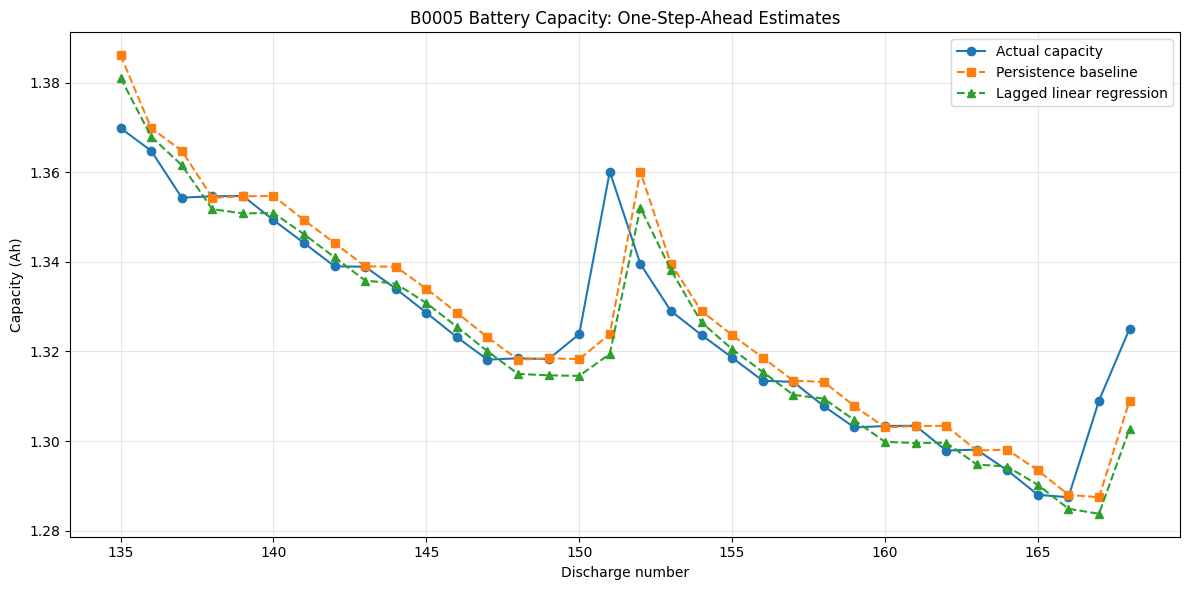

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(test_df["discharge_number"], y_test, marker="o", label="Actual capacity")
ax.plot(test_df["discharge_number"], persistence_pred, marker="s",
        linestyle="--", label="Persistence baseline")
ax.plot(test_df["discharge_number"], linear_pred, marker="^",
        linestyle="--", label="Lagged linear regression")
ax.set(title="B0005 Battery Capacity: One-Step-Ahead Estimates",
       xlabel="Discharge number", ylabel="Capacity (Ah)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 13. Inspect the largest one-step-ahead errors

In [14]:
error_analysis = test_df[["discharge_number", "capacity_Ah", "capacity_lag1"]].copy()
error_analysis = error_analysis.rename(columns={"capacity_Ah": "actual_capacity_Ah"})
error_analysis["persistence_prediction_Ah"] = persistence_pred
error_analysis["linear_prediction_Ah"] = linear_pred
error_analysis["linear_error_Ah"] = (
    error_analysis["linear_prediction_Ah"] - error_analysis["actual_capacity_Ah"]
)
error_analysis["absolute_error_Ah"] = error_analysis["linear_error_Ah"].abs()

display(
    error_analysis.sort_values("absolute_error_Ah", ascending=False)
    .head(10).round(4)
)

,discharge_number,actual_capacity_Ah,capacity_lag1,persistence_prediction_Ah,linear_prediction_Ah,linear_error_Ah,absolute_error_Ah
148,151,1.3601,1.3239,1.3239,1.3194,-0.0407,0.0407
164,167,1.3090,1.2875,1.2875,1.2838,-0.0253,0.0253
165,168,1.3251,1.3090,1.3090,1.3027,-0.0223,0.0223
149,152,1.3395,1.3601,1.3601,1.3521,0.0126,0.0126
132,135,1.3699,1.3861,1.3861,1.3811,0.0112,0.0112
147,150,1.3239,1.3183,1.3183,1.3145,-0.0093,0.0093
150,153,1.3290,1.3395,1.3395,1.3382,0.0091,0.0091
134,137,1.3543,1.3648,1.3648,1.3616,0.0073,0.0073
136,139,1.3547,1.3546,1.3546,1.3508,-0.0039,0.0039
158,161,1.3034,1.3034,1.3034,1.2996,-0.0039,0.0039


## 14. Export processed data and model metrics

Processed CSV files are written to the local `results/` directory. These are generated outputs; the raw NASA `.mat` file is not copied into the repository by this notebook.


In [15]:
capacity_csv = OUTPUT_DIR / "B0005_discharge_capacity.csv"
features_csv = OUTPUT_DIR / "B0005_discharge_curve_features.csv"
merged_csv = OUTPUT_DIR / "B0005_modeling_dataset.csv"

df_capacity.to_csv(capacity_csv, index=False)
df_features.to_csv(features_csv, index=False)
df_ml.to_csv(merged_csv, index=False)

metrics_frames = []
for frame, experiment in [
    (trend_results_df, "Experiment 1: discharge-number models"),
    (feature_results_df, "Experiment 2: retrospective feature models"),
    (forecast_results_df, "Experiment 3: one-step-ahead models"),
]:
    temp = frame.copy()
    temp.insert(0, "Experiment", experiment)
    metrics_frames.append(temp)

all_metrics_df = pd.concat(metrics_frames, ignore_index=True)
metrics_csv = OUTPUT_DIR / "B0005_model_comparison_metrics.csv"
all_metrics_df.to_csv(metrics_csv, index=False)

print("Exported processed files:")
for filename in [capacity_csv.name, features_csv.name, merged_csv.name, metrics_csv.name]:
    print("-", OUTPUT_DIR / filename)

display(all_metrics_df.round(4))


Exported processed files:
- results\B0005_discharge_capacity.csv
- results\B0005_discharge_curve_features.csv
- results\B0005_modeling_dataset.csv
- results\B0005_model_comparison_metrics.csv


,Experiment,Model,MAE (Ah),RMSE (Ah),R2 Score
0,Experiment 1: discharge-number models,Linear regression: discharge number,0.0309,0.0388,-2.0554
1,Experiment 1: discharge-number models,Random forest: discharge number,0.0506,0.0553,-5.1923
2,Experiment 1: discharge-number models,Last observed capacity baseline,0.0612,0.0651,-7.5803
3,Experiment 1: discharge-number models,Training mean baseline,0.3104,0.3111,-195.2336
4,Experiment 2: retrospective feature models,Linear regression: completed-discharge features,0.0027,0.0029,0.9831
5,Experiment 2: retrospective feature models,Random forest: completed-discharge features,0.0500,0.0545,-5.0229
6,Experiment 3: one-step-ahead models,Persistence baseline,0.0065,0.0100,0.7969
7,Experiment 3: one-step-ahead models,Lagged linear regression,0.0059,0.0101,0.7929


## 15. Conclusions and limitations


- The capacity and SOH plots summarize degradation across the recorded B0005 discharge cycles.
- Feature correlations describe associations in this dataset; they do not establish causation.
- The retrospective full-feature model uses measurements from the completed discharge and should not be described as a pre-discharge forecast.
- The rolling one-step-ahead models use recent measured capacities. Their scores do not represent a single multi-step forecast of the full test period.
- Compare both MAE and RMSE with the persistence baseline. A small improvement in one metric does not necessarily mean the model is clearly better overall.
- Capacity values may fluctuate between adjacent records. Do not automatically interpret an observed rebound as physical battery recovery.
- Only B0005 is analyzed here. Generalization to other cells, chemistries, operating conditions, or datasets has not been tested.

